# 01. Данные: структура сессий и нейрофизиология

Первый шаг решения — разобраться, что лежит в данных и какие признаки физиологически осмысленны.

* 56 сессий 14 участников (`<дата>_N<id>.mat`, номера N01…N18 с пропусками): ЭЭГ 21 канал 250 Гц, NIRS 18 каналов (HbO/HbR).
* `States`: 0 — подготовка (не оценивается), 1 — покой, 2 — левая кисть, 3 — правая кисть;
  `Blocks` — номер блока (7 блоков × 4 пробы); первый блок — калибровка, не оценивается.
* Оценка — окна 1 с с шагом 250 мс, целиком внутри одного сегмента `States` ∈ {1, 2, 3}.

Выводы этого ноутбука определили конвейер: сенсомоторные ритмы ЭЭГ (мю/бета, 8–30 Гц) над C3/C4
латерализованы, а гемодинамический ответ NIRS запаздывает на секунды — поэтому NIRS нужны лаги и
медленные фильтры, а слиянию — сглаживание по времени.

Все вычисления здесь — **разведочные** (оффлайн, по всей сессии); в решении (`solution/`) обработка
только причинная — см. `02_causal_pipeline.ipynb`.

In [1]:
import os, sys, json, time, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "assets":
    ROOT = ROOT.parent
SOL = ROOT / "solution"
sys.path.insert(0, str(SOL))
# каталог с сессиями *.mat (распакованный data.zip организаторов: data/Data/*.mat);
# переопределяется переменной окружения HORMIGAS_DATA
DATA = Path(os.environ.get("HORMIGAS_DATA", ROOT / "data" / "Data"))
SESSIONS = sorted(p for p in DATA.glob("*.mat") if p.name.lower() != "montage.mat")
MONTAGE = next((p for p in (DATA / "Montage.mat", DATA.parent / "Montage.mat") if p.exists()), None)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
CLASS_NAMES = {1: "покой", 2: "левая", 3: "правая"}
print("сессий:", len(SESSIONS), "| Montage.mat:", MONTAGE is not None)

сессий: 56 | Montage.mat: True


## 1. Обзор сессий

In [2]:
from session_io import load_session, window_ends

rows, cache = [], {}
t0 = time.time()
for p in SESSIONS:
    s = load_session(p)
    ends, y, blk = window_ends(s["states"], s["blocks"], s["eeg_fs"])
    scored = blk != 1
    rows.append(dict(session=p.stem, subject=p.stem.split("_")[-1],
                     duration_s=len(s["states"]) / s["eeg_fs"], eeg_fs=s["eeg_fs"],
                     n_blocks=int(s["blocks"].max()), has_nirs=s["hbo"] is not None,
                     nirs_fs=s["nirs_fs"], n_windows=int(scored.sum()),
                     **{f"win_{CLASS_NAMES[k]}": int(((y == k) & scored).sum()) for k in (1, 2, 3)}))
    cache[p.stem] = s
print(f"загружено за {time.time() - t0:.0f} с")
df = pd.DataFrame(rows)
df.head()

загружено за 13 с


,session,subject,duration_s,eeg_fs,n_blocks,has_nirs,nirs_fs,n_windows,win_покой,win_левая,win_правая
0,2025.12.01.16.04.01_N01,N01,598.200,250.0,7,True,12.50000,1550,777,385,388
1,2025.12.04.13.29.33_N01,N01,598.104,250.0,7,True,12.50000,1549,774,389,386
2,2025.12.08.14.19.05_N02,N02,596.748,250.0,7,True,12.50000,1547,772,389,386
3,2025.12.09.12.52.43_N01,N01,596.628,250.0,7,True,3.90625,1548,775,388,385
4,2025.12.11.12.13.46_N03,N03,596.904,250.0,7,True,12.50000,1549,773,389,387


In [3]:
print("участников:", df.subject.nunique(), "| сессий:", len(df))
print("сессий без NIRS:", int((~df.has_nirs).sum()), list(df.session[~df.has_nirs]))
print("частота ЭЭГ:", sorted(df.eeg_fs.unique()), "| частота NIRS:", sorted(df.nirs_fs.dropna().round(2).unique()))
print("длительность, с: медиана %.0f, min %.0f, max %.0f" % (df.duration_s.median(), df.duration_s.min(), df.duration_s.max()))
df.groupby("subject").agg(sessions=("session", "count"), windows=("n_windows", "sum")).T

участников: 14 | сессий: 56
сессий без NIRS: 2 ['2025.12.18.12.09.22_N03', '2025.12.18.15.02.14_N02']
частота ЭЭГ: [250.0] | частота NIRS: [3.91, 12.5]
длительность, с: медиана 597, min 596, max 598


subject,N01,N02,N03,N06,N08,N09,N10,N11,N13,N14,N15,N16,N17,N18
sessions,3,4,4,4,4,4,4,4,4,5,4,4,4,4
windows,4647,6197,6199,6196,6193,6195,6200,6201,6191,7740,6203,6199,6197,6188


In [4]:
tot = df[[f"win_{c}" for c in CLASS_NAMES.values()]].sum()
print("оцениваемые окна по классам (блоки 2–7, все сессии):")
print((tot / tot.sum()).round(3).to_string())
print("\nПокой — около половины окон: macro-recall и min-F1 требуют не «угадывать покой», а различать все 3 класса.")

оцениваемые окна по классам (блоки 2–7, все сессии):
win_покой     0.500
win_левая     0.251
win_правая    0.250

Покой — около половины окон: macro-recall и min-F1 требуют не «угадывать покой», а различать все 3 класса.


## 2. Протокол сессии

Блок = 4 пробы воображения (9 с) через покой (9 с) с подготовкой между ними; порядок левая/правая
внутри блока не фиксирован.

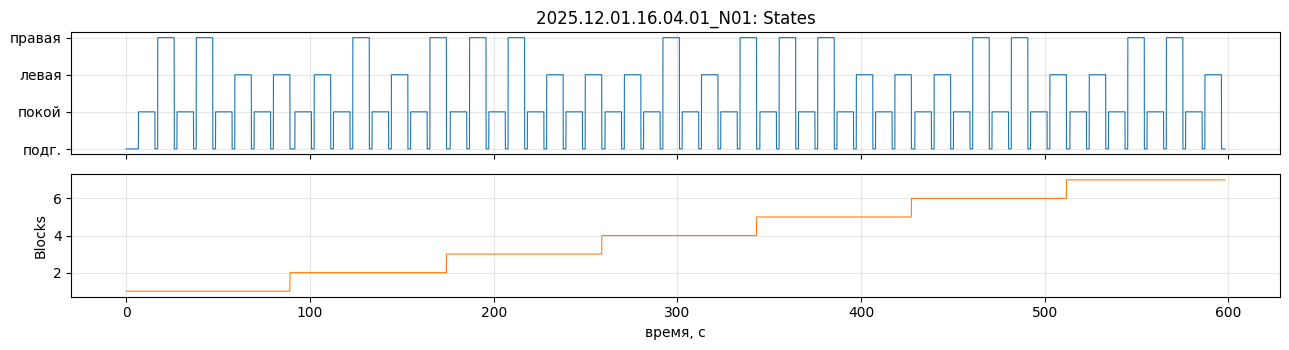

,count,mean,min,max
state,,,,
0,57.0,1.65,1.48,6.52
1,28.0,9.00,8.99,9.01
2,14.0,9.00,8.99,9.01
3,14.0,9.00,8.99,9.01


In [5]:
s = cache[SESSIONS[0].stem]
t = np.arange(len(s["states"])) / s["eeg_fs"]
fig, ax = plt.subplots(2, 1, figsize=(13, 3.6), sharex=True)
ax[0].plot(t, s["states"], lw=0.8); ax[0].set_yticks([0, 1, 2, 3], ["подг.", "покой", "левая", "правая"])
ax[0].set_title(f"{SESSIONS[0].stem}: States")
ax[1].plot(t, s["blocks"], lw=0.8, color="C1"); ax[1].set_ylabel("Blocks"); ax[1].set_xlabel("время, с")
plt.tight_layout(); plt.show()
seg = np.r_[0, np.flatnonzero(np.diff(s["states"])) + 1]
lens = pd.DataFrame({"state": s["states"][seg], "len_s": np.diff(np.r_[seg, len(s["states"])]) / s["eeg_fs"]})
lens.groupby("state").len_s.describe()[["count", "mean", "min", "max"]].round(2)

## 3. Монтаж ЭЭГ и NIRS

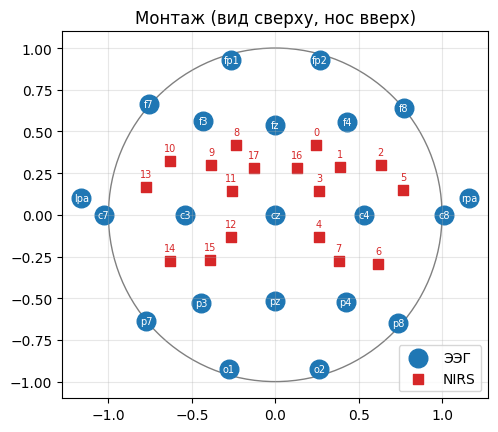

NIRS: каналы 0–7, 16 — правое полушарие (x > 0), 8–15, 17 — левое: x>0: [0, 1, 2, 3, 4, 5, 6, 7, 16]


In [6]:
import scipy.io as sio
if MONTAGE is not None:
    M = sio.loadmat(MONTAGE, squeeze_me=True, struct_as_record=False)["Montage"]
    ep, el, npos = np.asarray(M.EEG_positions), list(M.EEG_labels), np.asarray(M.NIRS_positions)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color="grey"))
    ax.scatter(ep[:, 0], ep[:, 1], s=180, c="C0", label="ЭЭГ")
    for (x, y), l in zip(ep, el):
        ax.text(x, y, l, ha="center", va="center", fontsize=7, color="w")
    ax.scatter(npos[:, 0], npos[:, 1], s=60, c="C3", marker="s", label="NIRS")
    for i, (x, y) in enumerate(npos):
        ax.text(x, y + 0.06, str(i), ha="center", fontsize=7, color="C3")
    ax.set_aspect("equal"); ax.legend(loc="lower right"); ax.set_title("Монтаж (вид сверху, нос вверх)")
    plt.show()
    print("NIRS: каналы 0–7, 16 — правое полушарие (x > 0), 8–15, 17 — левое:",
          "x>0:", list(np.flatnonzero(npos[:, 0] > 0)))

## 4. ЭЭГ: десинхронизация мю/бета-ритма при воображении

Для каждой сессии считаем спектр Уэлча по сегментам каждого класса (первые 0.5 с сегмента
отбрасываем) и сравниваем мощность в задаче с покоем: ERD = 10·log10(P_задача / P_покой), дБ.
Ожидание: воображение движения кисти подавляет мю/бета-ритм над контралатеральной моторной
корой (левая кисть → C4, правая → C3).

In [7]:
from scipy.signal import welch
LBL = ['fp1', 'fp2', 'f3', 'f4', 'c3', 'c4', 'p3', 'p4', 'o1', 'o2', 'f7', 'f8',
       'c7', 'c8', 'p7', 'p8', 'lpa', 'rpa', 'fz', 'cz', 'pz']       # порядок каналов в .mat
BANDS = {"мю 8–13": (8, 13), "бета 13–30": (13, 30)}

def class_psd(s, fs=250.0, skip=0.5):
    st, x = s["states"], s["eeg"] - s["eeg"].mean(0)
    seg = np.r_[0, np.flatnonzero(np.diff(st)) + 1, len(st)]
    acc = {k: [] for k in (1, 2, 3)}
    for a, b in zip(seg[:-1], seg[1:]):
        k = int(st[a])
        if k in acc and b - a > (skip + 2) * fs:
            f, P = welch(x[a + int(skip * fs):b], fs=fs, nperseg=int(fs), axis=0)
            acc[k].append(P)
    return f, {k: np.mean(v, 0) for k, v in acc.items() if v}

erd = []
np.seterr(divide="ignore", invalid="ignore")          # в части сессий есть «мёртвые» каналы
for name, s in cache.items():
    f, P = class_psd(s)
    if len(P) < 3:
        continue
    for bn, (lo, hi) in BANDS.items():
        m = (f >= lo) & (f < hi)
        for k in (2, 3):
            e = 10 * np.log10(P[k][m].mean(0) / P[1][m].mean(0))
            erd.append(dict(session=name, subject=name.split("_")[-1], band=bn, cls=CLASS_NAMES[k],
                            **{c: e[LBL.index(c)] for c in ("c3", "c4", "cz")}))
erd = pd.DataFrame(erd)
erd.groupby(["band", "cls"])[["c3", "c4", "cz"]].mean().round(2)

c3    c4    cz
band       cls                     
бета 13–30 левая  -0.54 -0.82 -0.36
           правая -0.38 -0.42 -0.52
мю 8–13    левая  -1.17 -1.77 -1.22
           правая -0.91 -1.25 -1.16

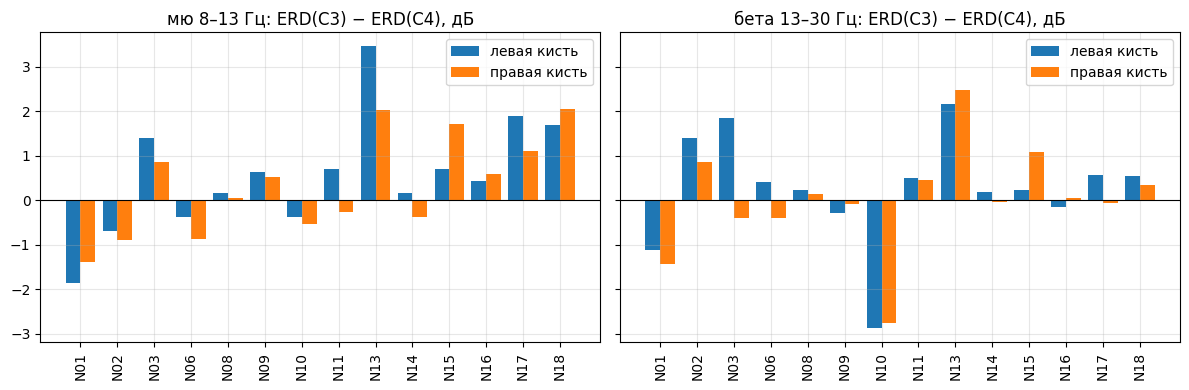

участников с ожидаемой латерализацией мю (правая < левая): 10 из 14


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, bn in zip(axes, BANDS):
    d = erd[erd.band == bn]
    lat = d.pivot_table(index="subject", columns="cls", values="c3") - d.pivot_table(index="subject", columns="cls", values="c4")
    # C3 − C4: при правой кисти C3 подавлен сильнее (меньше), при левой — C4
    x = np.arange(len(lat))
    ax.bar(x - 0.2, lat["левая"], 0.4, label="левая кисть")
    ax.bar(x + 0.2, lat["правая"], 0.4, label="правая кисть")
    ax.set_xticks(x, lat.index, rotation=90); ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{bn} Гц: ERD(C3) − ERD(C4), дБ"); ax.legend()
plt.tight_layout(); plt.show()
d = erd[erd.band == "мю 8–13"].assign(lat=lambda t: t.c3 - t.c4).groupby(["subject", "cls"]).lat.mean().unstack()
print("участников с ожидаемой латерализацией мю (правая < левая):", int((d["правая"] < d["левая"]).sum()), "из", len(d))

Десинхронизация при задаче видна у большинства участников, а латерализация «левая/правая» —
слабее и индивидуальна. Отсюда решения: (1) основной источник — ковариации фильтр-банка 4–30 Гц
(касательное пространство), учитывающие все каналы, а не только C3/C4; (2) межсубъектные пулы +
дообучение внутри сессии; (3) основная трудность — «левая vs правая», а не «задача vs покой».

## 5. NIRS: запаздывающий гемодинамический ответ

Усредняем HbO относительно начала сегментов (базовая линия — 2 с до начала) по полушариям.

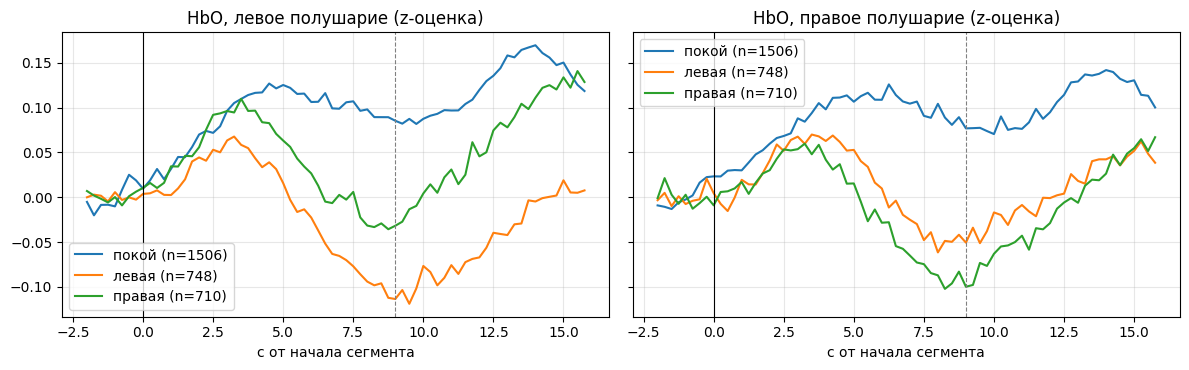

In [9]:
RIGHT_CH, LEFT_CH = list(range(0, 8)) + [16], list(range(8, 16)) + [17]
PRE, POST = 2.0, 16.0
tt = np.arange(-PRE, POST, 0.25)                      # общая шкала времени (частоты NIRS разные: 12.5 и 3.9 Гц)
ep = {k: {"L": [], "R": []} for k in (1, 2, 3)}
for name, s in cache.items():
    if s["hbo"] is None:
        continue
    fr, st = s["nirs_frame"], s["states"]
    z = (s["hbo"] - s["hbo"].mean(0)) / (s["hbo"].std(0) + 1e-12)
    on = np.flatnonzero(np.diff(st) != 0) + 1
    for a in on:
        k = int(st[a])
        if k not in ep:
            continue
        m = (fr >= a - PRE * 250) & (fr <= a + POST * 250)
        if m.sum() < 10 or fr[m][0] > a - (PRE - 0.5) * 250 or fr[m][-1] < a + (POST - 0.5) * 250:
            continue
        trel = (fr[m] - a) / 250.0
        for h, ch in (("L", LEFT_CH), ("R", RIGHT_CH)):
            v = np.interp(tt, trel, z[m][:, ch].mean(1))
            ep[k][h].append(v - v[tt < 0].mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, h, title in zip(axes, ("L", "R"), ("левое полушарие", "правое полушарие")):
    for k in (1, 2, 3):
        m = np.mean(ep[k][h], 0)
        ax.plot(tt, m, label=f"{CLASS_NAMES[k]} (n={len(ep[k][h])})")
    ax.axvline(0, color="k", lw=0.8); ax.axvline(9, color="grey", ls="--", lw=0.8)
    ax.set_title(f"HbO, {title} (z-оценка)"); ax.set_xlabel("с от начала сегмента"); ax.legend()
plt.tight_layout(); plt.show()

Кривые задачи и покоя расходятся только через 4–5 с после начала сегмента, а максимум
разницы приходится на 8–10 с, то есть на конец пробы (9 с). После конца пробы разница держится ещё
несколько секунд, так что мгновенное значение NIRS описывает прошлое. Латерализация тоже есть: в
каждом полушарии HbO выше при контралатеральной кисти (левое полушарие — правая, правое — левая),
но она заметно слабее разницы «задача / покой».

Отсюда решения для NIRS в конвейере:
* признаки — значения полосовых фильтров 0.005–0.5 Гц в текущий момент и на лагах назад;
* каскад «задача / покой» → «левая / правая»;
* «левая / правая» учится только на окнах, которые отстоят от начала сегмента не меньше чем на 3 с.

В слиянии NIRS в основном помогает отличить задачу от покоя, а латерализацию даёт ЭЭГ.

## Итоги

| наблюдение | решение в конвейере |
|---|---|
| покой ≈ половина окон, метрики — min-F1 и macro-recall | калиброванные вероятности + априорные сдвиги в слиянии |
| ERD мю/бета есть, латерализация слабая и индивидуальная | фильтр-банк → ковариации → касательное пространство, пулы по участникам |
| NIRS запаздывает на 5–10 с | лаговые признаки, каскад, многомасштабное сглаживание в слиянии |
| 2 сессии без NIRS | деградация до ЭЭГ-only (отдельная мета-модель) |